# CMPSC 105 Lab 09: Coffee Queue Catastrophes

**Scenario:** The campus coffee shop is receiving complaints about unpredictable drink volumes for a "small" orders. Some are overflowing, while others look half-empty. The student newspaper has meticulously recorded the data logs for 100 recent orders. Your job is to build two different prediction models, K-Nearest Neighbors and Linear Regression, to estimate the final volume of a drink in ounces based on the milk temperature and the number of syrup pumps added.

Author: Oscar Zúñiga

## Part 1: Generating the Coffee Logs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

np.random.seed(42)
n_orders = 100

# Features: Milk Temp (large scale), Syrup Pumps (small scale)
milk_temp = np.random.uniform(130, 170, n_orders)
syrup_pumps = np.random.uniform(0, 5, n_orders)

# Target: Coffee Volume (oz)
# Base 6.7628 oz + 0.2705 oz per pump + slight expansion from hot milk + noise
volume_oz = 6.7628 + (syrup_pumps * 0.2705) + (milk_temp * 0.0067628) + np.random.normal(0, 0.1014, n_orders)

coffee_df = pd.DataFrame({
    'milk_temp_f': np.round(milk_temp, 1),
    'syrup_pumps': np.round(syrup_pumps, 1),
    'volume_oz': np.round(volume_oz, 1)
})

print(coffee_df.head())


   milk_temp_f  syrup_pumps  volume_oz
0        145.0          0.2        7.7
1        168.0          3.2        8.8
2        159.3          1.6        8.3
3        153.9          2.5        8.4
4        136.2          4.5        9.1


#### Part 1: Distance Calc

A new order comes in: 150°F milk, with 4 pumps of syrup. Without using `scikit-learn` yet, let's see how the computer calculates the raw Euclidean distance between this new order and two historical logs.

In [3]:
new_order = np.array([150, 4])

# Log A: Milk is very close in temp, but NO syrup
log_a = np.array([152, 0]) 

# Log B: Milk is much colder, but EXACTLY the same syrup
log_b = np.array([140, 4]) 

dist_to_a = np.sqrt(np.sum((new_order - log_a)**2))
dist_to_b = np.sqrt(np.sum((new_order - log_b)**2))

print(f"Unscaled Distance to Log A (152F, 0 pumps): {dist_to_a:.1f}")
print(f"Unscaled Distance to Log B (140F, 4 pumps): {dist_to_b:.1f}")


Unscaled Distance to Log A (152F, 0 pumps): 4.5
Unscaled Distance to Log B (140F, 4 pumps): 10.0


**Question 1**: Which log does the math say is "closer"? Why does this mathematical reality completely fail the physical reality of liquid volume in a coffee cup? (Hint: Think about how much 4 pumps of syrup affects the liquid volume versus a 10-degree temperature difference. This is a conceptual question!)

The math says Log A is closer because of its smaller distance, but that's misleading. Since we didn't scale the data, the huge temperature numbers completely took out the syrup pumps. In the real world, four pumps of syrup are going to mess with your drink volume way more than a 10 degree temperature change, which is why we need to scale our features first.

#### Part 2: Standardizing and KNN
To fix this, we scale the features so 1 "unit" of temperature has the same mathematical weight as 1 "unit" of syrup.

In [4]:
X = coffee_df[['milk_temp_f', 'syrup_pumps']]
y = coffee_df['volume_oz']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
new_order_scaled = scaler.transform([new_order])

# Fit KNN and Predict
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_scaled, y)
knn_prediction = knn.predict(new_order_scaled)

print(f"KNN Predicted Volume (K=5): {knn_prediction[0]:.1f} oz")


KNN Predicted Volume (K=5): 9.0 oz


/Users/oscarzuniga_m/Documents/CMPSC105/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


**Question 2**: We used $K=5$ neighbors. If we changed the algorithm to use $K=100$ (the entire dataset), what exact number in ounces would the model predict for every single cup of coffee?

If you set K = 100, the model would predict the exact same number for every single cup: the overall average volume of the entire dataset. Since it's looking at all 100 data points for every prediction, it just calculates the mean of all those drink volumes.

#### Part 3: Linear Regression
Linear Regression doesn't necessarily need scaling to work. It figures out the physical rules on its own.


In [5]:
lin_reg = LinearRegression()
lin_reg.fit(X, y)

print(f"Intercept (Base Volume): {lin_reg.intercept_:.2f} oz")
print(f"Milk Temp Coefficient:   {lin_reg.coef_[0]:.4f} oz per degree F")
print(f"Syrup Pump Coefficient:  {lin_reg.coef_[1]:.2f} oz per pump")


Intercept (Base Volume): 6.91 oz
Milk Temp Coefficient:   0.0057 oz per degree F
Syrup Pump Coefficient:  0.28 oz per pump


**Question 3**: Write out the exact mathematical formula your model discovered for predicting coffee volume. According to your model's rules, exactly how many ounces of liquid does one pump of syrup add to the cup?


The formula the model discovered is:

Volume = 6.91 + (0.0057 x Milk Temp) + (0.28 x Syrup Pumps)

Here one pump of syrup adds 0.28 ounces of liquid to the cup.

#### Part 4: Residuals 
No model is perfect. Let's see where our linear formula performed poorly.


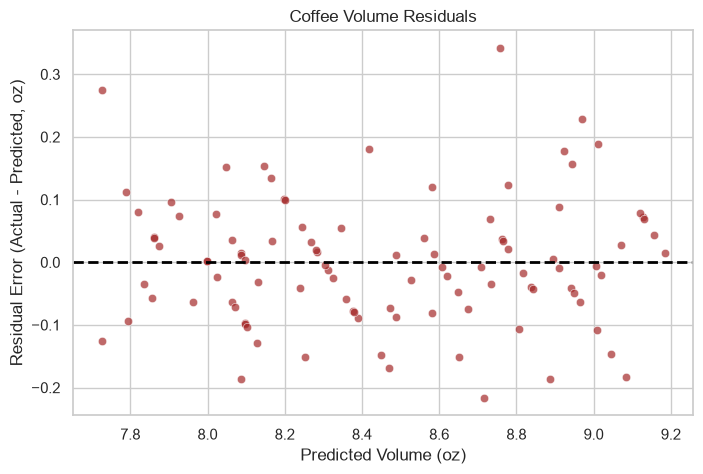

Worst Under-prediction (Highest Positive Residual): 0.3 oz
Actual volume was 9.1 oz, but model predicted 8.8 oz.


In [6]:
predictions = lin_reg.predict(X)
residuals = y - predictions

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.scatterplot(x=predictions, y=residuals, alpha=0.7, color='brown')
plt.axhline(0, color='black', linestyle='--', lw=2)
plt.title("Coffee Volume Residuals")
plt.xlabel("Predicted Volume (oz)")
plt.ylabel("Residual Error (Actual - Predicted, oz)")
plt.show()

max_resid_idx = np.argmax(residuals)
print(f"Worst Under-prediction (Highest Positive Residual): {residuals[max_resid_idx]:.1f} oz")
print(f"Actual volume was {y.iloc[max_resid_idx]:.1f} oz, but model predicted {predictions[max_resid_idx]:.1f} oz.")


**Question 4**: Find the data point with the highest positive residual (printed above). Write a 2-3 sentence explanation theorizing what physical coffee shop mistake (barista error, machine malfunction, etc.) caused this specific cup to have significantly more liquid than the math predicted.


The extra liquid likely came from a simple barista mistake, like accidentally pouring too much milk or adding unlogged pumps of syrup.

**Question 5**: If the newspaper editor asks you why the model predicts a specific cup will be 10 ounces, how would you explain the reasoning using the K-Nearest Neighbors model versus the Linear Regression model? Which model provides a better explanation for the newspaper staff?


K-Nearest Neighbors explains the prediction by looking at similar past orders, while Linear Regression uses a formula that adds specific amounts for each ingredient. Linear Regression is better for the newspaper staff because it shows exactly how each ingredient impacts the final volume.